In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import correlate, correlation_lags

# 측정 설정
fs = 5e9
t = np.arange(0, 1e-6, 1/fs)
v = 2e8

# 기준 신호: 가우시안 포락선을 씌운 처프 (논문의 기준 신호와 같은 구조)
def gaussian_chirp(t, t_center, fc=200e6, bandwidth=200e6, sigma=15e-9):
    tau = t - t_center
    k = bandwidth / (4 * sigma)
    envelope = np.exp(-tau**2 / (2 * sigma**2))
    return envelope * np.cos(2*np.pi*(fc*tau + 0.5*k*tau**2))

t0 = 50e-9
ref = gaussian_chirp(t, t0)

# 케이블 고장 설정
d_fault = 30
gamma = -0.5
tau = 2 * d_fault / v

# 측정 지점에서 받는 신호 = 보낸 처프 + 늦게 돌아온 반사파 + 잡음
rng = np.random.default_rng(0)
received = ref + gamma * gaussian_chirp(t, t0 + tau) + 0.2 * rng.standard_normal(len(t))

print(f"실제 지연 시간: {tau*1e9:.1f} ns")

실제 지연 시간: 300.0 ns


## 결과 예상
1. 실제 지연 시간은? -> t = s/2v = 2*30/(200000000) = 300ns
2. 받은 신호(recevied)를 그래프로 그리면 반사파가 눈에 잘 보일까?
- 입사파(50ns)와 반사파(50+t ns)는 시간상 떨어져 있어 겹치지 않는다.
- 반사파 크기 0.5, 잡음 표준편차 0.2 -> 반사파가 잘 보인다. 왜냐하면, 반사파 크기 0.5가 잡음 표준 편차의 2.5배라서.
3. 상호상관 결과에서 봉우리는 몇 개, 어느 시각에 나올까?
- 0 ns 근처: 입사파 봉우리, 방향은 양, 크기는 제곱
- t ns 근처: 반사파 봉우리, 방향은 음수, 크기는 입사파 봉우리의 약 0.5^2 -> 1/4 배

추정 지연 시간: 300.0 ns
추정 고장 위치: 30.00 m (실제 30 m)


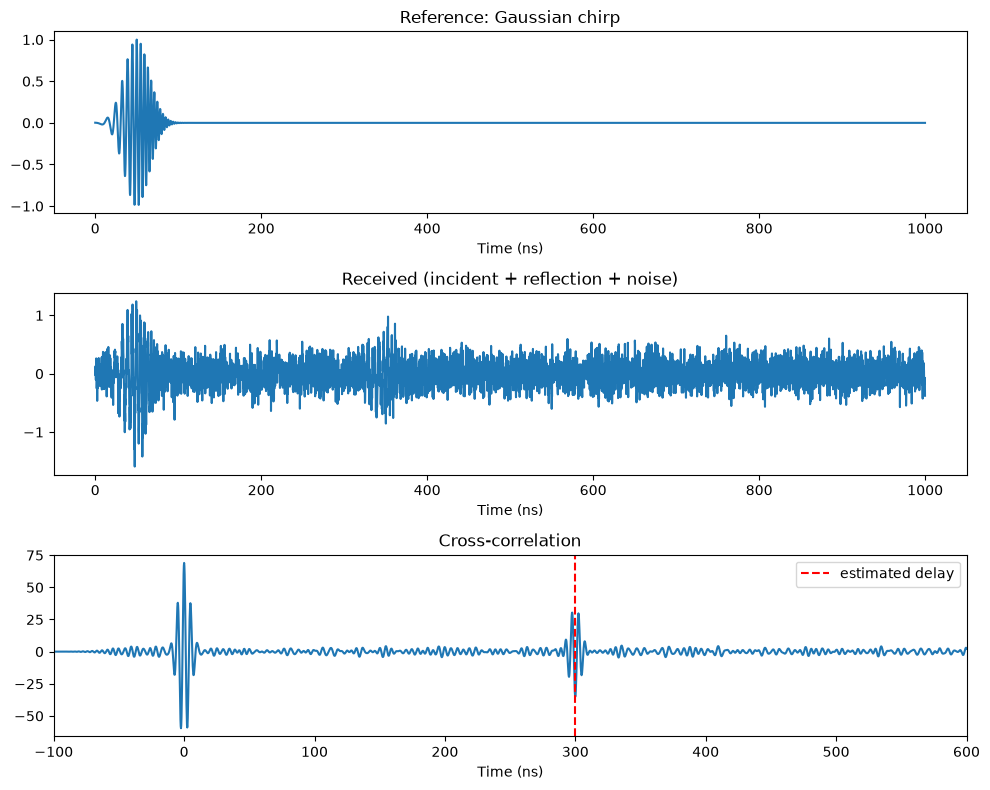

In [2]:
# 받은 신호 위에서 기준 처프를 밀어 가며 얼마나 비슷한지 계산
c = correlate(received, ref, mode='full')
lags = correlation_lags(len(received), len(ref), mode='full') / fs

# 0초 근처(보낸 신호 자체)를 제외하고 가장 큰 봉우리 찾기
mask = lags > 100e-9
idx = np.argmax(np.abs(c[mask]))
tau_est = lags[mask][idx]
d_est = v * tau_est / 2

print(f"추정 지연 시간: {tau_est*1e9:.1f} ns")
print(f"추정 고장 위치: {d_est:.2f} m (실제 {d_fault} m)")

fig, ax = plt.subplots(3, 1, figsize=(10, 8))
ax[0].plot(t*1e9, ref)
ax[0].set_title("Reference: Gaussian chirp")
ax[1].plot(t*1e9, received)
ax[1].set_title("Received (incident + reflection + noise)")
ax[2].plot(lags*1e9, c)
ax[2].axvline(tau_est*1e9, color="red", linestyle="--", label="estimated delay")
ax[2].set_title("Cross-correlation")
ax[2].set_xlim(-100, 600)
ax[2].legend()
for a in ax:
    a.set_xlabel("Time (ns)")
plt.tight_layout()
plt.show()

In [3]:
i0 = np.argmin(np.abs(lags))          # 0 ns 위치
i1 = np.argmin(np.abs(lags - tau))    # 실제 지연 시간 위치

print(f"입사파 봉우리 값: {c[i0]:.2f}")
print(f"반사파 봉우리 값: {c[i1]:.2f}")
print(f"비율 (반사파 / 입사파): {c[i1] / c[i0]:.3f}")

입사파 봉우리 값: 68.99
반사파 봉우리 값: -35.06
비율 (반사파 / 입사파): -0.508


## 실험 결과 (예상과 비교)
1. 지연 시간: 예상 300 ns -> 추정 300 ns, 고장 위치 30 m로 정확히 맞았다
2. 받은 신호에서 반사파: 예상 "잘 보인다" -> 일부분 정답
- 350 ns(보낸 시각 50 ns + 왕복 300 ns)에 반사파 덩어리가 보이긴 한다.
- 하지만 잡음도 곳곳에서 튀어서, 위치를 모르면 반사파인지 잡음인지 확신하기 어렵다
3. 상호상관 봉우리:
- 0 ns: 입사파 봉우리, 양의 방향 -> 맞음
- 300 ns: 반사파 봉우리, 음의 방향 -> 맞음
- 크기 비율: 예상 -0.25 -> 실제 -0.508 -> 틀림

## 해석
- 비율이 -0.25가 아니라 -0.5인 이유:
    상호상관은 received * ref 를 곱해서 더하는데, 감마는 received에만 한 번 들어 있다. 그래서 봉우리 크기는 감마에 한 번만 비례한다. (위그너 분포처럼 자기 자신과 곱하는 방식이면 감마가 두 번 곱해진다)
- 0.500이 아니라 0.508인 이유: 잡음 때문
- 상호상관 봉우리가 350 ns가 아니라 300 ns인 이유:
    가로축은 실제 시간이 아니라 "기준 처프를 얼마나 밀었을 때 가장 잘 맞았는가"이다. 기준 처프도 50 ns에 있으므로 300 ns만큼 밀면 맞는다.
    -> 봉우리 위치 = 왕복 지연 시간 -> 바로 거리로 환산 가능
- 봉우리가 바늘이 아니라 위아래로 흔들리는 덩어리인 이유: 신호가 200 MHz로 빠르게 진동하기 때문이다

## 처프 + 상호상관을 쓰는 이유 (이 실험의 핵심)
1. 잡음 대비 반사파가 뚜렷해진다
    - 받은 신호: 반사파 약 0.5 / 잡음 표준편차 0.2 -> 약 2.5배
    - 상호상관: 반사파 봉우리 약 35 / 바닥 출렁임 약 +- 3 -> 약 10배 이상
    - 잡음은 곱해서 더하면 양수, 음수가 상쇄되고 반사파는 기준과 모양이 같아 차곡차곡 쌓이기 때문이다
2. 덩어리가 좁아진다 (펄스 압축)
    - 받은 신호의 반사파 덩어리 폭 약 80 ns -> 상호상관 봉우리 폭 약 20 ns
    - 덩어리가 좁을수록 가까이 붙은 고장 두 개를 구분하기 쉽다
3. 봉우리 크기 비율로 감마를 알 수 있다
    - 거리뿐 아니라 고장의 종류(부호: + 끊어짐 쪽, - 합선 쪽)와 심한 정도(크기)까지 추정 가능

## 결론 및 다음 단계
- 시간 영역 상호상관으로 고장 위치(30 m)와 반사 계수 (약 -0.5)를 모두 추정했다.
- 다음(02): 잡음 크기(0.2 -> 0.5, 1, 2)와 고장 위치를 바꿔가며 어디까지 정확히 찾는지 확인한다.
- 이후(03): 시간-주파수 상호상관(위그너 분포)으로 바꿔 비교하고, 그때 봉우리 비율이 감마^2 (0.25)에 가까어지는지 확인한다.